In [1]:
import matplotlib.pyplot as plt

from baymorph import SyntheticSersic

In [2]:
galaxy = SyntheticSersic(
    flux=10000,
    re=10,
    n=4,
    q=0.7,
    theta=0.5,
    x0=50,
    y0=50,
)

image = galaxy.render(
    shape=(100, 100)
)

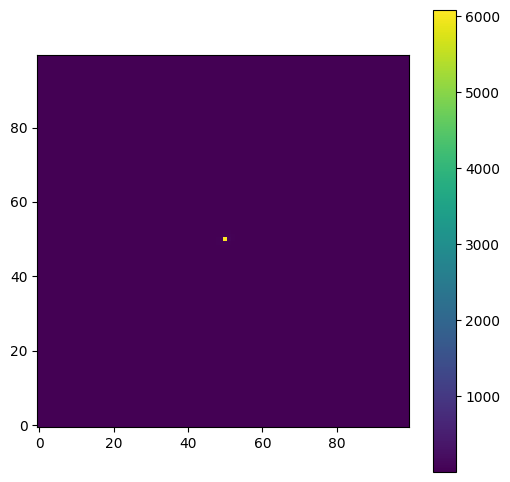

In [3]:
plt.figure(figsize=(6, 6))

plt.imshow(
    image,
    origin="lower",
)

plt.colorbar()

plt.show()

In [4]:
image.sum()

np.float64(9999.999999999996)

In [5]:
from baymorph import (
    DynestyFluxFitter,
    SersicModel,
    make_constant_noise_map,
)

In [6]:
true_flux = 1000.0

data = SersicModel(
    flux=true_flux,
    re=8.0,
    n=2.0,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
).render(
    shape=(60, 60)
)

In [7]:
noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

In [8]:
def model_factory(flux):

    return SersicModel(
        flux=flux,
        re=8.0,
        n=2.0,
        q=0.8,
        theta=0.0,
        x0=30.0,
        y0=30.0,
    )

In [9]:
fitter = DynestyFluxFitter(
    model_factory=model_factory,
    data=data,
    noise=noise,
    flux_min=100.0,
    flux_max=2000.0,
)

In [10]:
result = fitter.run(
    nlive=50
)

iter: 332 | +50 | bound: 6 | nc: 1 | ncall: 1969 | eff(%): 19.906 | loglstar:   -inf < -3308.179 <    inf | logz: -3311.893 +/-  0.252 | dlogz:  0.001 >  0.059                                       

In [11]:
result.flux_median

1000.5302640167014

In [12]:
print("True flux:", true_flux)
print("Recovered flux:", result.flux_median)

True flux: 1000.0
Recovered flux: 1000.5302640167014


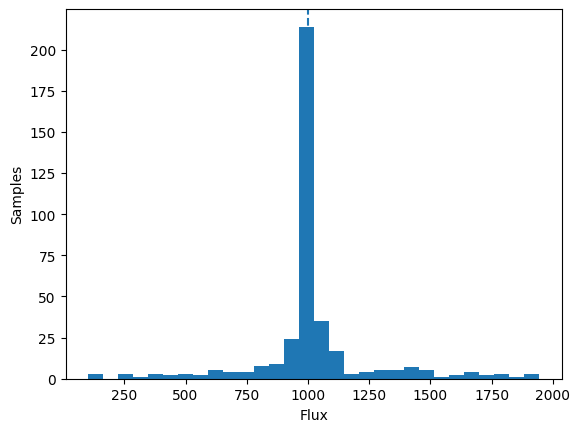

In [13]:
plt.hist(
    result.samples[:,0],
    bins=30,
)

plt.axvline(
    true_flux,
    linestyle="--",
)

plt.xlabel("Flux")
plt.ylabel("Samples")
plt.show()